# Modeling

This notebook develops the first machine-learning models for the Rio de Janeiro ITBI dataset.

The modeling strategy is built progressively. 
We first use a simple and well-defined subset of the data: residential transactions from 2016. 
This makes it easier to compare different targets and algorithms without mixing several sources of complexity at once.

The notebook then expands the analysis to non-residential properties and, finally, to the full time series.

The main evaluation metrics are:
- **MAE**: mean absolute error;
- **MSE**: mean squared error;
- **RMSE**: root mean squared error;
- **R²**: proportion of the target variance explained by the model.

# Import
The processed dataset and the required modeling libraries are loaded below. 
Two dictionaries are also created to store model scores and predictions throughout the notebook.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
filepath = "../data/processed/ITBI_featured.xlsx"

dfs_dict = pd.read_excel(filepath, sheet_name=None, index_col=0)

df = dfs_dict["transacoes"]
df_bairro = dfs_dict["bairro"]
df_logradouro = dfs_dict["logradouro"]
df_tipologia = dfs_dict["tipologia"]
df_descricao = dfs_dict["descricao"]

In [3]:
df.info()

<class 'pandas.DataFrame'>
Index: 490160 entries, 0 to 79934
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ano                490160 non-null  int64  
 1   mes                490160 non-null  int64  
 2   COD_REGIAO_FISCAL  490160 non-null  str    
 3   COD_BAIRRO         490160 non-null  int64  
 4   COD_LOGRADOURO     490160 non-null  int64  
 5   COD_TRECHO         490160 non-null  int64  
 6   COD_TIPOLOGIA      490160 non-null  int64  
 7   ID_UTILIZACAO      490160 non-null  int64  
 8   FATOR_IDADE        477434 non-null  float64
 9   vl_declarado       490160 non-null  float64
 10  area               490160 non-null  int64  
 11  valor_m2           490160 non-null  float64
 12  count_anterior     439493 non-null  float64
 13  median_anterior    439493 non-null  float64
 14  mean_anterior      439493 non-null  float64
 15  std_anterior       439493 non-null  float64
dtypes: float64(7), int6

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ano,490160.0,2020.734283,3.216833e+00,2016.000000,2018.000000,2021.000000,2024.000000,2.026000e+03
mes,490160.0,6.702707,3.380533e+00,1.000000,4.000000,7.000000,10.000000,1.200000e+01
COD_BAIRRO,490160.0,79.934627,4.933388e+01,-1.000000,28.000000,79.000000,128.000000,1.650000e+02
COD_LOGRADOURO,490160.0,96766.047054,9.171504e+04,-1.000000,48579.000000,73460.000000,103549.000000,7.790400e+05
COD_TRECHO,490160.0,3.116154,6.677949e+00,-1.000000,1.000000,1.000000,2.000000,1.100000e+02
COD_TIPOLOGIA,490160.0,11.996358,1.120912e+01,1.000000,10.000000,10.000000,10.000000,9.900000e+01
ID_UTILIZACAO,490160.0,1.183010,5.149819e-01,1.000000,1.000000,1.000000,1.000000,5.000000e+00
FATOR_IDADE,477434.0,0.740856,1.744863e-01,0.500000,0.550000,0.800000,0.850000,1.000000e+00
vl_declarado,490160.0,668901.830684,1.461321e+06,472.500000,220000.000000,372477.700000,689760.765000,9.976000e+07
area,490160.0,167.071974,1.028480e+03,6.000000,49.000000,70.000000,103.000000,9.925300e+04


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

In [6]:
models_performance_dict, y_pred_dict = dict(), dict()

# First approach: residential properties in 2016

The first experiments use only residential transactions (`ID_UTILIZACAO = 1`) from 2016.

Starting with a single year avoids temporal drift while the basic modeling choices are tested. 
It also keeps the problem focused on the largest and most homogeneous property-usage group.

The first questions are:
1. Should the model predict value per square meter or total declared value?
2. Does a logarithmic target improve the results?
3. Which regression algorithm provides the best balance between accuracy and generalization?

In [7]:
df_2016_type1 = df[
    (df.ano == 2016) & (df.ID_UTILIZACAO == 1)
]
df_2016_type1.describe().T

,count,mean,std,min,25%,50%,75%,max
ano,40573.0,2016.000000,0.000000,2016.000000,2016.00,2016.000000,2016.000000,2.016000e+03
mes,40573.0,7.064600,3.338364,1.000000,4.00,7.000000,10.000000,1.200000e+01
COD_BAIRRO,40573.0,80.167131,46.223981,1.000000,33.00,76.000000,124.000000,1.590000e+02
COD_LOGRADOURO,40573.0,83168.870012,60935.233399,59.000000,40832.00,71811.000000,98319.000000,4.962400e+05
COD_TRECHO,40573.0,2.633525,5.246600,-1.000000,1.00,1.000000,2.000000,1.100000e+02
COD_TIPOLOGIA,40573.0,9.614842,6.896812,2.000000,10.00,10.000000,10.000000,9.400000e+01
ID_UTILIZACAO,40573.0,1.000000,0.000000,1.000000,1.00,1.000000,1.000000,1.000000e+00
FATOR_IDADE,40573.0,0.792023,0.204911,0.500000,0.57,0.860000,1.000000,1.000000e+00
vl_declarado,40573.0,623901.828486,990672.233312,4576.050000,250000.00,410205.000000,680000.000000,3.800000e+07
area,40573.0,88.747394,69.810015,10.000000,56.00,71.000000,95.000000,1.861000e+03


In [8]:
df_2016_type1.isna().sum()

ano                      0
mes                      0
COD_REGIAO_FISCAL        0
COD_BAIRRO               0
COD_LOGRADOURO           0
COD_TRECHO               0
COD_TIPOLOGIA            0
ID_UTILIZACAO            0
FATOR_IDADE              0
vl_declarado             0
area                     0
valor_m2                 0
count_anterior       40573
median_anterior      40573
mean_anterior        40573
std_anterior         40573
dtype: int64

In [9]:
print("Number of:")
print("  Typology:", df_2016_type1.COD_TIPOLOGIA.nunique())
print("  Neighborhoods:", df_2016_type1.COD_BAIRRO.nunique())
print("  Streets:", df_2016_type1.COD_LOGRADOURO.nunique())
print("  Passage:", df_2016_type1.COD_TRECHO.nunique())

Number of:
  Typology: 10
  Neighborhoods: 155
  Streets: 3621
  Passage: 36


In [10]:
def calc_scores(model_name, y_pred_train, y_pred_test, X_train, X_test, y_train, y_test, add_to_dict=True):
    
    # store predictions
    y_pred_dict[(model_name, "train")] = y_pred_train.copy()
    y_pred_dict[(model_name, "test")] = y_pred_test.copy()

    # train scores
    MAE_train = mean_absolute_error(y_train, y_pred_train, multioutput="raw_values")
    MSE_train = mean_squared_error(y_train, y_pred_train)
    RMSE_train = root_mean_squared_error(y_train, y_pred_train)
    R2_train = r2_score(y_train, y_pred_train)
    
    # test scores
    MAE_test = mean_absolute_error(y_test, y_pred_test, multioutput="raw_values")
    MSE_test = mean_squared_error(y_test, y_pred_test)
    RMSE_test = root_mean_squared_error(y_test, y_pred_test)
    R2_test = r2_score(y_test, y_pred_test) 

    if add_to_dict:

        # train scores
        models_performance_dict[(model_name, "MAE" , "train")] = MAE_train
        models_performance_dict[(model_name, "MSE" , "train")] = MSE_train
        models_performance_dict[(model_name, "RMSE", "train")] = RMSE_train
        models_performance_dict[(model_name, "R2"  , "train")] = R2_train
        
        # test scores
        models_performance_dict[(model_name, "MAE" , "test")] = MAE_test
        models_performance_dict[(model_name, "MSE" , "test")] = MSE_test
        models_performance_dict[(model_name, "RMSE", "test")] = RMSE_test
        models_performance_dict[(model_name, "R2"  , "test")] = R2_test

    else:
        return MAE_train, MSE_train, RMSE_train, R2_train, MAE_test, MSE_test, RMSE_test, R2_test

## Linear regression

Linear regression is used as the first baseline.

The initial target is `valor_m2`. 
Categorical location and property-type variables are one-hot encoded. 
Property area is transformed to log space and standardized, while `FATOR_IDADE` is scaled separately.

This simple model provides a reference point before moving to more flexible algorithms.

In [11]:
X, y = df_2016_type1.drop(["valor_m2", "vl_declarado"], axis=1), df_2016_type1.valor_m2
X_train, X_test, y_train, y_test = train_test_split(X, y)

In [12]:
preprocessor = ColumnTransformer([
    (
        "location",
        OneHotEncoder(handle_unknown="ignore"),
        ["COD_TIPOLOGIA", "COD_BAIRRO","COD_LOGRADOURO"]
    ),
    (
        "log_area",
        Pipeline([
            ("log", FunctionTransformer(np.log, inverse_func=np.exp, feature_names_out="one-to-one")), # convert to log space
            ("scaler", StandardScaler())
        ]),
        ["area"]
    ),
    (
        "age_factor",
        Pipeline([
            ("scaler", MinMaxScaler())
        ]),
        ["FATOR_IDADE"]
    )
])

In [13]:
lr1_model = Pipeline([
    ("preprocesor", preprocessor),
    ("regressor", LinearRegression())
])
lr1_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['ano','mes','COD_REGIAO_FISCAL',...,'median_anterior','mean_anterior', 'std_anterior']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('location', ...), ('log_area', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pass

In [14]:
calc_scores(
    "LR-1",
    lr1_model.predict(X_train),
    lr1_model.predict(X_test),
    X_train, X_test, y_train, y_test
)

pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1])

0                                                    \
           train                                              test   
             MAE           MSE         RMSE        R2          MAE   
LR-1  1085.93894  4.576198e+06  2139.205042  0.780109  1253.807092   

                                           
                                           
               MSE         RMSE        R2  
LR-1  4.727213e+06  2174.215441  0.742186

The first model predicts `valor_m2` directly. The next experiment keeps the same features and model, but trains the regression on log(`valor_m2`).

Using a logarithmic target can be useful because valor_m2 is strongly right-skewed. Predictions are transformed back to the original scale before the evaluation metrics are calculated.

In [15]:
lr2_model = Pipeline([
    ("preprocesor", preprocessor),
    ("regressor", LinearRegression())
])
lr2_model.fit(X_train, np.log(y_train))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['ano','mes','COD_REGIAO_FISCAL',...,'median_anterior','mean_anterior', 'std_anterior']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('location', ...), ('log_area', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pass

In [16]:
calc_scores(
    "LR-2",
    np.exp(lr2_model.predict(X_train)),
    np.exp(lr2_model.predict(X_test)),
    X_train, X_test, y_train, y_test
)

pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1])

0                                                    \
            train                                              test   
              MAE           MSE         RMSE        R2          MAE   
LR-1  1085.938940  4.576198e+06  2139.205042  0.780109  1253.807092   
LR-2  1086.265326  5.055822e+06  2248.515443  0.757062  1206.328911   

                                           
                                           
               MSE         RMSE        R2  
LR-1  4.727213e+06  2174.215441  0.742186  
LR-2  4.379200e+06  2092.653784  0.761166

The improvement from using log(`valor_m2`) is limited.

The next experiment changes the target from value per square meter to the total declared transaction value, `vl_declarado`.

This is closer to the final valuation problem. 
Property area remains available as an input feature, so the model can learn how total value changes with size, location, property age, and typology.

In [17]:
X, y = df_2016_type1.drop(["valor_m2", "vl_declarado"], axis=1), df_2016_type1.vl_declarado
X_train, X_test, y_train, y_test = train_test_split(X, y)

In [18]:
lr3_model = Pipeline([
    ("preprocesor", preprocessor),
    ("regressor", LinearRegression())
])
lr3_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['ano','mes','COD_REGIAO_FISCAL',...,'median_anterior','mean_anterior', 'std_anterior']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('location', ...), ('log_area', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pass

In [19]:
calc_scores(
    "LR-3",
    lr3_model.predict(X_train),
    lr3_model.predict(X_test),
    X_train, X_test, y_train, y_test
)

pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1])

0                                                        \
              train                                                  test   
                MAE           MSE           RMSE        R2            MAE   
LR-1    1085.938940  4.576198e+06    2139.205042  0.780109    1253.807092   
LR-2    1086.265326  5.055822e+06    2248.515443  0.757062    1206.328911   
LR-3  169124.333629  2.439731e+11  493936.298740  0.753124  189481.641982   

                                             
                                             
               MSE           RMSE        R2  
LR-1  4.727213e+06    2174.215441  0.742186  
LR-2  4.379200e+06    2092.653784  0.761166  
LR-3  2.262666e+11  475674.853852  0.764500

The direct prediction of `vl_declarado` does not improve the results substantially.

The next model keeps total declared value as the target, but fits the regression in log space.
The predictions are then converted back to reais before the metrics are calculated.

In [20]:
lr4_model = Pipeline([
    ("preprocesor", preprocessor),
    ("regressor", LinearRegression())
])
lr4_model.fit(X_train, np.log(y_train))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['ano','mes','COD_REGIAO_FISCAL',...,'median_anterior','mean_anterior', 'std_anterior']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('location', ...), ('log_area', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pass

In [21]:
calc_scores(
    "LR-4",
    np.exp(lr4_model.predict(X_train)),
    np.exp(lr4_model.predict(X_test)),
    X_train, X_test, y_train, y_test
)
pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1])

0                                                        \
              train                                                  test   
                MAE           MSE           RMSE        R2            MAE   
LR-1    1085.938940  4.576198e+06    2139.205042  0.780109    1253.807092   
LR-2    1086.265326  5.055822e+06    2248.515443  0.757062    1206.328911   
LR-3  169124.333629  2.439731e+11  493936.298740  0.753124  189481.641982   
LR-4  106091.953192  1.400695e+11  374258.656258  0.858264  115973.057540   

                                             
                                             
               MSE           RMSE        R2  
LR-1  4.727213e+06    2174.215441  0.742186  
LR-2  4.379200e+06    2092.653784  0.761166  
LR-3  2.262666e+11  475674.853852  0.764500  
LR-4  2.165513e+11  465350.689275  0.774612

This formulation performs noticeably better.

The model reaches a training R² of about 0.86 and a test R² of about 0.77. 
The difference between both scores indicates some loss of generalization, but the result is strong enough to use this formulation as the linear baseline.

The scatter plot below compares the observed and predicted declared values on logarithmic axes.

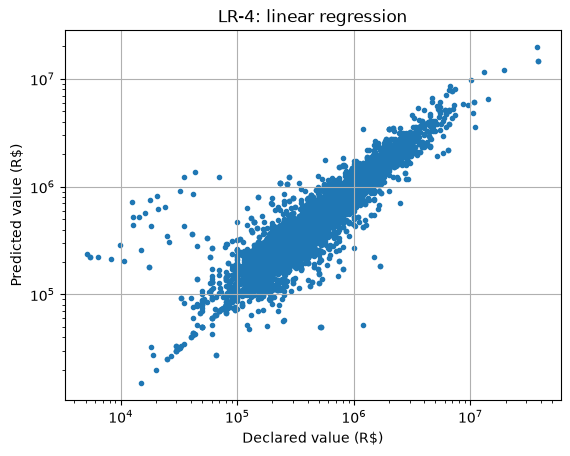

In [22]:
fig, ax = plt.subplots()
ax.scatter(y_test, y_pred_dict[("LR-4", "test")], marker=".")
ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title("LR-4: linear regression")
ax.set_xlabel("Declared value (R$)")
ax.set_ylabel("Predicted value (R$)")
ax.grid()

The points broadly follow the expected diagonal trend, although the dispersion increases for some price ranges. This is consistent with the limitations of a linear model: the real-estate market contains nonlinear effects and interactions between location, size, and other property characteristics.

Before testing more complex models, permutation importance is used to estimate how much each original input variable contributes to the prediction.

Permutation importance measures how much model performance deteriorates when one feature is randomly shuffled. A larger decrease indicates that the fitted model relies more strongly on that variable.

In [23]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    lr4_model,
    X,
    np.log(y),
    scoring="explained_variance",
)

df_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": result.importances_mean,
    "std": result.importances_std
}).sort_values("importance", ascending=False).set_index("feature")

df_importance

,importance,std
feature,,
COD_BAIRRO,0.959861,0.004555
area,0.446232,0.002792
COD_LOGRADOURO,0.403110,0.002763
FATOR_IDADE,0.074346,0.000867
COD_TIPOLOGIA,0.003449,0.000114
ano,0.000000,0.000000
mes,0.000000,0.000000
COD_REGIAO_FISCAL,0.000000,0.000000
COD_TRECHO,0.000000,0.000000


The neighborhood (`COD_BAIRRO`) is the most influential variable in this linear model. 
Property area comes next, followed closely by the street (`COD_LOGRADOURO`). 
`FATOR_IDADE` has a smaller but still measurable contribution.

The variables with zero importance are not necessarily irrelevant to the real-estate market. 
Several of them are simply not included in the current preprocessor, so the model does not use them.

The next sections compare more flexible regression algorithms using the same general prediction problem.

## Ridge

Ridge regression keeps the linear structure of the previous model but adds L2 regularization.

Regularization penalizes very large coefficients. 
This can be useful when the one-hot encoding creates many correlated or sparse features, especially for variables such as neighborhood and street.

In [24]:
from sklearn.linear_model import Ridge

In [25]:
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=1.0))
])
ridge_model.fit(X_train, np.log(y_train))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['ano','mes','COD_REGIAO_FISCAL',...,'median_anterior','mean_anterior', 'std_anterior']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('location', ...), ('log_area', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

In [26]:
calc_scores(
    "Ridge",
    np.exp(ridge_model.predict(X_train)),
    np.exp(ridge_model.predict(X_test)),
    X_train, X_test, y_train, y_test
)
pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1])

0                                                        \
               train                                                  test   
                 MAE           MSE           RMSE        R2            MAE   
LR-1     1085.938940  4.576198e+06    2139.205042  0.780109    1253.807092   
LR-2     1086.265326  5.055822e+06    2248.515443  0.757062    1206.328911   
LR-3   169124.333629  2.439731e+11  493936.298740  0.753124  189481.641982   
LR-4   106091.953192  1.400695e+11  374258.656258  0.858264  115973.057540   
Ridge  113690.402186  1.656489e+11  406999.885955  0.832380  118353.416901   

                                              
                                              
                MSE           RMSE        R2  
LR-1   4.727213e+06    2174.215441  0.742186  
LR-2   4.379200e+06    2092.653784  0.761166  
LR-3   2.262666e+11  475674.853852  0.764500  
LR-4   2.165513e+11  465350.689275  0.774612  
Ridge  2.447154e+11  494687.220602  0.745298

Ridge produces a smaller difference between training and test performance, but its test score is lower than the unregularized log-linear model.

This suggests that regularization improves coefficient stability, but the main limitation is probably the linear form of the model rather than excessive coefficient magnitude.

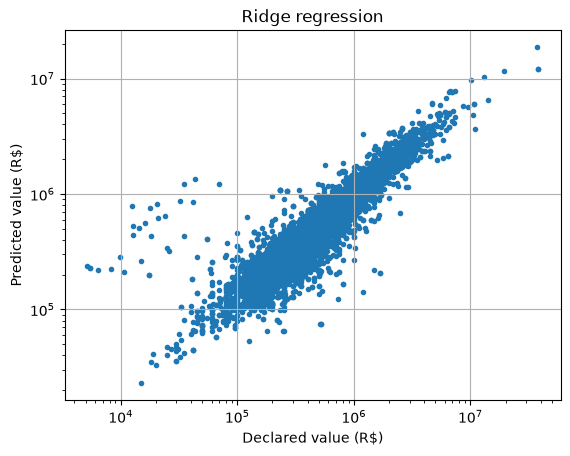

In [27]:
fig, ax = plt.subplots()
ax.scatter(y_test, y_pred_dict[("Ridge", "test")], marker=".")
ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title("Ridge regression")
ax.set_xlabel("Declared value (R$)")
ax.set_ylabel("Predicted value (R$)")
ax.grid()

The predicted-versus-observed plot has a similar overall shape to the previous linear regression.

This reinforces the idea that improving the model will likely require nonlinear relationships rather than another variation of the same linear structure.

## Random forest

Random Forest is the first nonlinear model tested.

Unlike linear regression, decision trees can naturally capture thresholds and interactions between variables. The ensemble combines many trees to reduce the instability of an individual tree.

In [28]:
from sklearn.ensemble import RandomForestRegressor

In [29]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor())
])
rf_model.fit(X_train, np.log(y_train))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['ano','mes','COD_REGIAO_FISCAL',...,'median_anterior','mean_anterior', 'std_anterior']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('location', ...), ('log_area', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

In [30]:
calc_scores(
    "RF",
    np.exp(rf_model.predict(X_train)),
    np.exp(rf_model.predict(X_test)),
    X_train, X_test, y_train, y_test
)
pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1])

0                                                        \
               train                                                  test   
                 MAE           MSE           RMSE        R2            MAE   
LR-1     1085.938940  4.576198e+06    2139.205042  0.780109    1253.807092   
LR-2     1086.265326  5.055822e+06    2248.515443  0.757062    1206.328911   
LR-3   169124.333629  2.439731e+11  493936.298740  0.753124  189481.641982   
LR-4   106091.953192  1.400695e+11  374258.656258  0.858264  115973.057540   
RF      47944.308891  2.072993e+10  143978.916213  0.979023   88188.238692   
Ridge  113690.402186  1.656489e+11  406999.885955  0.832380  118353.416901   

                                              
                                              
                MSE           RMSE        R2  
LR-1   4.727213e+06    2174.215441  0.742186  
LR-2   4.379200e+06    2092.653784  0.761166  
LR-3   2.262666e+11  475674.853852  0.764500  
LR-4   2.165513e+11  465350.689275  0.774612  
RF     1.035804e+11  321839.022933  0.892193  
Ridge  2.447154e+11  494687.220602  0.745298

Random Forest gives the strongest predictive performance so far, with a test R² of about 0.89.

Its training R² is much higher, at about 0.98. This larger train-test gap suggests that the model fits the training data very closely and may have higher variance.

The model is also more computationally expensive than the linear alternatives. These trade-offs will be considered when selecting the model for further development.

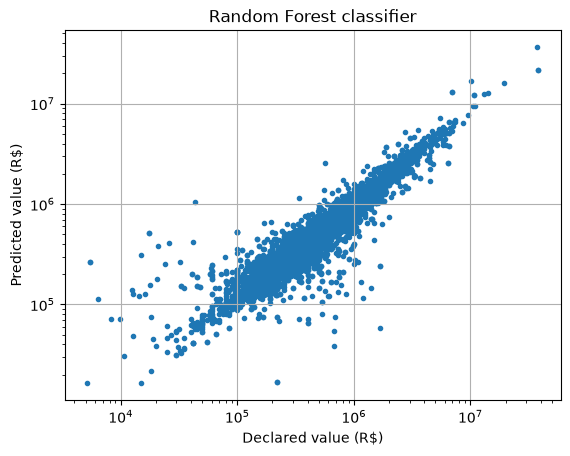

In [31]:
fig, ax = plt.subplots()
ax.scatter(y_test, y_pred_dict[("RF", "test")], marker=".")
ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title("Random Forest classifier")
ax.set_xlabel("Declared value (R$)")
ax.set_ylabel("Predicted value (R$)")
ax.grid(True)

## XGBoost

XGBoost is another tree-based ensemble method, but it builds trees sequentially through gradient boosting.

Each new tree focuses on errors left by the previous trees. XGBoost also provides several forms of regularization and efficient tools for controlling model complexity, which makes it a strong candidate for larger tabular datasets.

In [32]:
from xgboost import XGBRegressor

In [33]:
xg_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor())
])
xg_model.fit(X_train, np.log(y_train))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['ano','mes','COD_REGIAO_FISCAL',...,'median_anterior','mean_anterior', 'std_anterior']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('location', ...), ('log_area', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

In [34]:
calc_scores(
    "XGBoost",
    np.exp(xg_model.predict(X_train)),
    np.exp(xg_model.predict(X_test)),
    X_train, X_test, y_train, y_test
)
pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1])

0                                                        \
                 train                                                  test   
                   MAE           MSE           RMSE        R2            MAE   
LR-1       1085.938940  4.576198e+06    2139.205042  0.780109    1253.807092   
LR-2       1086.265326  5.055822e+06    2248.515443  0.757062    1206.328911   
LR-3     169124.333629  2.439731e+11  493936.298740  0.753124  189481.641982   
LR-4     106091.953192  1.400695e+11  374258.656258  0.858264  115973.057540   
RF        47944.308891  2.072993e+10  143978.916213  0.979023   88188.238692   
Ridge    113690.402186  1.656489e+11  406999.885955  0.832380  118353.416901   
XGBoost  117509.347551  1.002456e+11  316615.895737  0.898562  123884.132309   

                                                
                                                
                  MSE           RMSE        R2  
LR-1     4.727213e+06    2174.215441  0.742186  
LR-2     4.379200e+06    2092.653784  0.761166  
LR-3     2.262666e+11  475674.853852  0.764500  
LR-4     2.165513e+11  465350.689275  0.774612  
RF       1.035804e+11  321839.022933  0.892193  
Ridge    2.447154e+11  494687.220602  0.745298  
XGBoost  1.248261e+11  353307.384758  0.870080

XGBoost reaches a test R² of about 0.87. This is slightly below Random Forest, but the train-test gap is much smaller.

That balance is important. The goal is not only to fit the 2016 sample well, but to build a model that can later be applied to larger and more heterogeneous datasets.

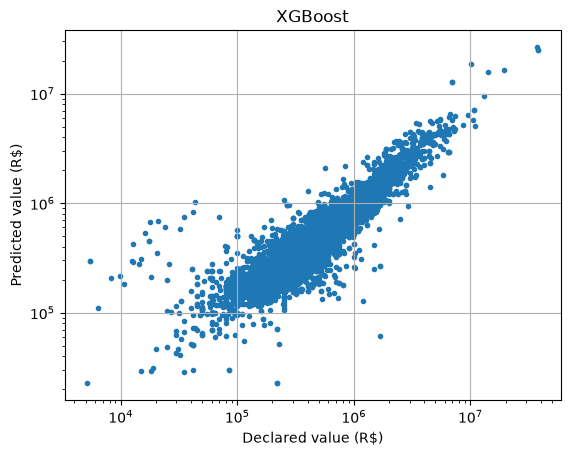

In [35]:
fig, ax = plt.subplots()
ax.scatter(y_test, y_pred_dict[("XGBoost", "test")], marker=".")
ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title("XGBoost")
ax.set_xlabel("Declared value (R$)")
ax.set_ylabel("Predicted value (R$)")
ax.grid(True)

## Model comparison
The table below collects the performance of all models tested so far. The following cell also calculates the difference between training and test scores to make the generalization gap easier to compare.

In [36]:
df_scores = pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1]).droplevel(0, axis=1)
df_scores

train                                                  test  \
                   MAE           MSE           RMSE        R2            MAE   
LR-1       1085.938940  4.576198e+06    2139.205042  0.780109    1253.807092   
LR-2       1086.265326  5.055822e+06    2248.515443  0.757062    1206.328911   
LR-3     169124.333629  2.439731e+11  493936.298740  0.753124  189481.641982   
LR-4     106091.953192  1.400695e+11  374258.656258  0.858264  115973.057540   
RF        47944.308891  2.072993e+10  143978.916213  0.979023   88188.238692   
Ridge    113690.402186  1.656489e+11  406999.885955  0.832380  118353.416901   
XGBoost  117509.347551  1.002456e+11  316615.895737  0.898562  123884.132309   

                                                
                  MSE           RMSE        R2  
LR-1     4.727213e+06    2174.215441  0.742186  
LR-2     4.379200e+06    2092.653784  0.761166  
LR-3     2.262666e+11  475674.853852  0.764500  
LR-4     2.165513e+11  465350.689275  0.774612  
RF       1.035804e+11  321839.022933  0.892193  
Ridge    2.447154e+11  494687.220602  0.745298  
XGBoost  1.248261e+11  353307.384758  0.870080

In [37]:
df_scores.train - df_scores.test

,MAE,MSE,RMSE,R2
LR-1,-167.868152,-1.510146e+05,-35.010399,0.037923
LR-2,-120.063585,6.766218e+05,155.861659,-0.004104
LR-3,-20357.308353,1.770650e+10,18261.444888,-0.011375
LR-4,-9881.104348,-7.648172e+10,-91092.033017,0.083652
RF,-40243.929801,-8.285043e+10,-177860.106720,0.086831
Ridge,-4663.014715,-7.906654e+10,-87687.334647,0.087082
XGBoost,-6374.784758,-2.458048e+10,-36691.489021,0.028482


Among the strongest models, the results show different trade-offs:
- **Ridge Regression** is fast and relatively stable, but its lower scores suggest that a linear model cannot fully represent the relationships in the data.
- **Random Forest** achieves the best test performance in this first experiment. However, it also has the largest training score and a wider train-test gap, together with a higher computational cost.
- **XGBoost** performs close to Random Forest while keeping a smaller train-test gap. It also supports nonlinear interactions, regularization, and efficient hyperparameter tuning.

For these reasons, XGBoost is selected as the main model for the next stages. It offers a good compromise between predictive performance, generalization, computational efficiency, and scalability.

# Generalizing the XGBoost model

The previous section focused only on residential transactions from 2016.

The next experiments test how the selected XGBoost model behaves when the problem becomes broader. We first evaluate non-residential properties and then examine whether residential and non-residential transactions should be modeled together.

## Non-residential properties
The first generalization test uses only non-residential transactions (`ID_UTILIZACAO = 2`) from 2016.

The objective is to check whether the same model structure also works for this smaller and more heterogeneous market segment.

In [53]:
df_2016_type2 = df[
    (df.ano == 2016) & (df.ID_UTILIZACAO.isin([2]))
]
df_2016_type2.describe().T

,count,mean,std,min,25%,50%,75%,max
ano,8186.0,2016.000000,0.000000e+00,2016.000000,2016.000000,2016.000000,2016.000000,2.016000e+03
mes,8186.0,6.793428,3.401600e+00,1.000000,4.000000,7.000000,10.000000,1.200000e+01
COD_BAIRRO,8186.0,73.894087,5.328582e+01,1.000000,16.000000,73.000000,128.000000,1.580000e+02
COD_LOGRADOURO,8186.0,77182.966773,4.892610e+04,1446.000000,42606.000000,63933.000000,95471.000000,2.280310e+05
COD_TRECHO,8186.0,4.776814,7.027594e+00,1.000000,1.000000,1.000000,4.000000,9.000000e+01
COD_TIPOLOGIA,8186.0,36.493281,2.109764e+01,2.000000,28.000000,28.000000,36.000000,9.900000e+01
ID_UTILIZACAO,8186.0,2.000000,0.000000e+00,2.000000,2.000000,2.000000,2.000000,2.000000e+00
FATOR_IDADE,8186.0,0.937466,9.850331e-02,0.650000,0.880000,1.000000,1.000000,1.000000e+00
vl_declarado,8186.0,692940.367297,2.806993e+06,4000.000000,160138.675000,240000.000000,395320.000000,4.366973e+07
area,8186.0,198.035304,1.329405e+03,7.000000,24.000000,28.000000,40.000000,2.020800e+04


In [54]:
df_2016_type2.isna().sum()

ano                     0
mes                     0
COD_REGIAO_FISCAL       0
COD_BAIRRO              0
COD_LOGRADOURO          0
COD_TRECHO              0
COD_TIPOLOGIA           0
ID_UTILIZACAO           0
FATOR_IDADE             0
vl_declarado            0
area                    0
valor_m2                0
count_anterior       8186
median_anterior      8186
mean_anterior        8186
std_anterior         8186
dtype: int64

In [55]:
print("Number of:")
print("  Typology:", df_2016_type2.COD_TIPOLOGIA.nunique())
print("  Neighborhoods:", df_2016_type2.COD_BAIRRO.nunique())
print("  Streets:", df_2016_type2.COD_LOGRADOURO.nunique())
print("  Passage:", df_2016_type2.COD_TRECHO.nunique())

Number of:
  Typology: 14
  Neighborhoods: 119
  Streets: 581
  Passage: 29


In [56]:
X, y = df_2016_type2.drop(["valor_m2", "vl_declarado"], axis=1), df_2016_type2.vl_declarado
X_train, X_test, y_train, y_test = train_test_split(X, y)

In [57]:
ml_tp2_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor())
])
ml_tp2_model.fit(X_train, np.log(y_train))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['ano','mes','COD_REGIAO_FISCAL',...,'median_anterior','mean_anterior', 'std_anterior']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('location', ...), ('log_area', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

In [58]:
calc_scores(
    "XGBoost 1 : Type 2 only",
    np.exp(ml_tp2_model.predict(X_train)),
    np.exp(ml_tp2_model.predict(X_test)),
    X_train, X_test, y_train, y_test,
    
)
pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1])

0                               \
                                      train                                
                                        MAE           MSE           RMSE   
LR-1                            1085.938940  4.576198e+06    2139.205042   
LR-2                            1086.265326  5.055822e+06    2248.515443   
LR-3                          169124.333629  2.439731e+11  493936.298740   
LR-4                          106091.953192  1.400695e+11  374258.656258   
RF                             47944.308891  2.072993e+10  143978.916213   
Ridge                         113690.402186  1.656489e+11  406999.885955   
XGBoost                       117509.347551  1.002456e+11  316615.895737   
XGBoost 1 : Type 2 only       120568.539099  2.940261e+11  542241.739157   
XGBoost 2 : Types 1 and 2     129238.124137  2.101917e+11  458466.693175   
XGBoost 2.1 : Type 1 (slice)  121788.282350  1.088196e+11  329878.085115   
XGBoost 2.2 : Type 2 (slice)  166014.461621  7.106180e+11  842981.612101   

                                                                     \
                                                 test                 
                                    R2            MAE           MSE   
LR-1                          0.780109    1253.807092  4.727213e+06   
LR-2                          0.757062    1206.328911  4.379200e+06   
LR-3                          0.753124  189481.641982  2.262666e+11   
LR-4                          0.858264  115973.057540  2.165513e+11   
RF                            0.979023   88188.238692  1.035804e+11   
Ridge                         0.832380  118353.416901  2.447154e+11   
XGBoost                       0.898562  123884.132309  1.248261e+11   
XGBoost 1 : Type 2 only       0.962532  151548.448906  6.631207e+11   
XGBoost 2 : Types 1 and 2     0.910013  141609.671631  3.650659e+11   
XGBoost 2.1 : Type 1 (slice)  0.896697  128383.523576  1.407546e+11   
XGBoost 2.2 : Type 2 (slice)  0.917946  207962.370957  1.490387e+12   

                                                      
                                                      
                                      RMSE        R2  
LR-1                          2.174215e+03  0.742186  
LR-2                          2.092654e+03  0.761166  
LR-3                          4.756749e+05  0.764500  
LR-4                          4.653507e+05  0.774612  
RF                            3.218390e+05  0.892193  
Ridge                         4.946872e+05  0.745298  
XGBoost                       3.533074e+05  0.870080  
XGBoost 1 : Type 2 only       8.143222e+05  0.916803  
XGBoost 2 : Types 1 and 2     6.042069e+05  0.764735  
XGBoost 2.1 : Type 1 (slice)  3.751728e+05  0.816174  
XGBoost 2.2 : Type 2 (slice)  1.220814e+06  0.728760

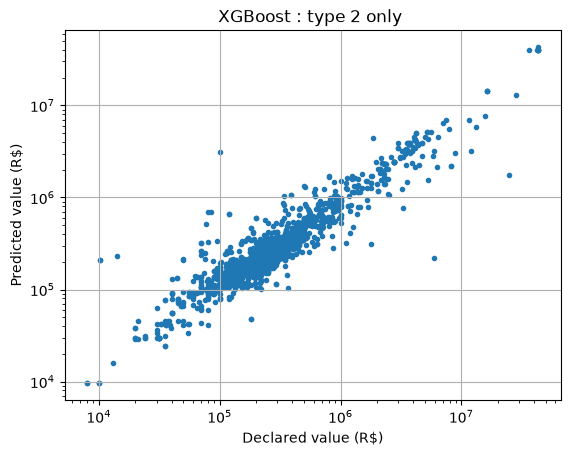

In [59]:
fig, ax = plt.subplots()
ax.scatter(y_test, y_pred_dict[("XGBoost 1 : Type 2 only", "test")], marker=".")
ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title("XGBoost : type 2 only ")
ax.set_xlabel("Declared value (R$)")
ax.set_ylabel("Predicted value (R$)")
ax.grid(True)

## Combining residential and non-residential properties
Residential and non-residential transactions together represent most of the observations in the dataset.

A single model covering both groups would therefore increase the practical scope of the estimator. However, the two property uses may follow different valuation patterns.

Land and common-area categories are not included in this experiment. 
These categories often have different physical characteristics, and `FATOR_IDADE` is frequently not available because no building is involved.

In [60]:
df_2016 = df[
    (df.ano == 2016) & (df.ID_UTILIZACAO.isin([1, 2]))
]
df_2016.describe().T

,count,mean,std,min,25%,50%,75%,max
ano,48759.0,2016.000000,0.000000e+00,2016.000000,2016.000000,2016.000,2016.000000,2.016000e+03
mes,48759.0,7.019073,3.350562e+00,1.000000,4.000000,7.000,10.000000,1.200000e+01
COD_BAIRRO,48759.0,79.113969,4.754026e+01,1.000000,33.000000,76.000,125.000000,1.590000e+02
COD_LOGRADOURO,48759.0,82163.914949,5.913167e+04,59.000000,40931.000000,70631.000,95471.000000,4.962400e+05
COD_TRECHO,48759.0,2.993355,5.642489e+00,-1.000000,1.000000,1.000,2.000000,1.100000e+02
COD_TIPOLOGIA,48759.0,14.127382,1.467071e+01,2.000000,10.000000,10.000,10.000000,9.900000e+01
ID_UTILIZACAO,48759.0,1.167887,3.737697e-01,1.000000,1.000000,1.000,1.000000,2.000000e+00
FATOR_IDADE,48759.0,0.816441,1.988040e-01,0.500000,0.640000,0.910,1.000000,1.000000e+00
vl_declarado,48759.0,635492.498490,1.462876e+06,4000.000000,225000.000000,380000.000,650000.000000,4.366973e+07
area,48759.0,107.095408,5.499121e+02,7.000000,48.000000,67.000,91.000000,2.020800e+04


In [61]:
df_2016.isna().sum()

ano                      0
mes                      0
COD_REGIAO_FISCAL        0
COD_BAIRRO               0
COD_LOGRADOURO           0
COD_TRECHO               0
COD_TIPOLOGIA            0
ID_UTILIZACAO            0
FATOR_IDADE              0
vl_declarado             0
area                     0
valor_m2                 0
count_anterior       48759
median_anterior      48759
mean_anterior        48759
std_anterior         48759
dtype: int64

In [62]:
print("Number of:")
print("  Typology:", df_2016.COD_TIPOLOGIA.nunique())
print("  Neighborhoods:", df_2016.COD_BAIRRO.nunique())
print("  Streets:", df_2016.COD_LOGRADOURO.nunique())
print("  Passage:", df_2016.COD_TRECHO.nunique())

Number of:
  Typology: 19
  Neighborhoods: 155
  Streets: 3825
  Passage: 40


The combined dataset does not introduce many additional streets compared with the residential-only subset.

The next step is therefore to train one XGBoost model on both usage types and compare its performance with the specialized models.

In [63]:
X, y = df_2016.drop(["valor_m2", "vl_declarado"], axis=1), df_2016.vl_declarado
X_train, X_test, y_train, y_test = train_test_split(X, y)

In [64]:
ml1_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor())
])
ml1_model.fit(X_train, np.log(y_train))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['ano','mes','COD_REGIAO_FISCAL',...,'median_anterior','mean_anterior', 'std_anterior']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('location', ...), ('log_area', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pas

In [65]:
calc_scores(
    "XGBoost 2 : Types 1 and 2",
    np.exp(ml1_model.predict(X_train)),
    np.exp(ml1_model.predict(X_test)),
    X_train, X_test, y_train, y_test
)
pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1])

0                               \
                                      train                                
                                        MAE           MSE           RMSE   
LR-1                            1085.938940  4.576198e+06    2139.205042   
LR-2                            1086.265326  5.055822e+06    2248.515443   
LR-3                          169124.333629  2.439731e+11  493936.298740   
LR-4                          106091.953192  1.400695e+11  374258.656258   
RF                             47944.308891  2.072993e+10  143978.916213   
Ridge                         113690.402186  1.656489e+11  406999.885955   
XGBoost                       117509.347551  1.002456e+11  316615.895737   
XGBoost 1 : Type 2 only       120568.539099  2.940261e+11  542241.739157   
XGBoost 2 : Types 1 and 2     126646.356326  1.961473e+11  442885.210595   
XGBoost 2.1 : Type 1 (slice)  121788.282350  1.088196e+11  329878.085115   
XGBoost 2.2 : Type 2 (slice)  166014.461621  7.106180e+11  842981.612101   

                                                                     \
                                                 test                 
                                    R2            MAE           MSE   
LR-1                          0.780109    1253.807092  4.727213e+06   
LR-2                          0.757062    1206.328911  4.379200e+06   
LR-3                          0.753124  189481.641982  2.262666e+11   
LR-4                          0.858264  115973.057540  2.165513e+11   
RF                            0.979023   88188.238692  1.035804e+11   
Ridge                         0.832380  118353.416901  2.447154e+11   
XGBoost                       0.898562  123884.132309  1.248261e+11   
XGBoost 1 : Type 2 only       0.962532  151548.448906  6.631207e+11   
XGBoost 2 : Types 1 and 2     0.903343  145543.435325  4.325827e+11   
XGBoost 2.1 : Type 1 (slice)  0.896697  128383.523576  1.407546e+11   
XGBoost 2.2 : Type 2 (slice)  0.917946  207962.370957  1.490387e+12   

                                                      
                                                      
                                      RMSE        R2  
LR-1                          2.174215e+03  0.742186  
LR-2                          2.092654e+03  0.761166  
LR-3                          4.756749e+05  0.764500  
LR-4                          4.653507e+05  0.774612  
RF                            3.218390e+05  0.892193  
Ridge                         4.946872e+05  0.745298  
XGBoost                       3.533074e+05  0.870080  
XGBoost 1 : Type 2 only       8.143222e+05  0.916803  
XGBoost 2 : Types 1 and 2     6.577102e+05  0.824972  
XGBoost 2.1 : Type 1 (slice)  3.751728e+05  0.816174  
XGBoost 2.2 : Type 2 (slice)  1.220814e+06  0.728760

The combined model shows a larger difference between training and test performance than the original residential-only model.

To understand where this loss occurs, the next cells inspect predictions by property usage and calculate the scores separately for residential and non-residential observations.

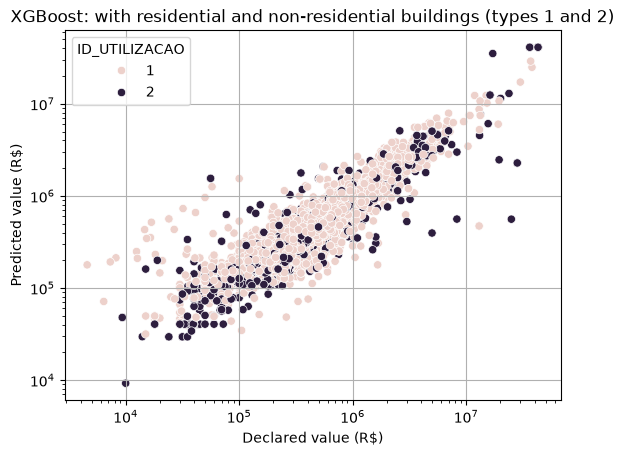

In [66]:
sns.scatterplot(
    x=y_test, 
    y=y_pred_dict[("XGBoost 2 : Types 1 and 2", "test")],
    hue=X_test.ID_UTILIZACAO
)

plt.title("XGBoost: with residential and non-residential buildings (types 1 and 2)")
plt.xlabel("Declared value (R$)")
plt.ylabel("Predicted value (R$)")
plt.xscale('log')
plt.yscale('log')
plt.grid()

In [67]:
mask1_train = X_train.ID_UTILIZACAO == 1
mask1_test = X_test.ID_UTILIZACAO == 1
type1_scores_list = calc_scores(
    "XGBoost 2.1 : Type 1 (slice)",
    np.exp(ml1_model.predict(X_train[mask1_train])),
    np.exp(ml1_model.predict(X_test[mask1_test])),
    X_train[mask1_train], X_test[mask1_test], y_train[mask1_train], y_test[mask1_test],
    add_to_dict=True
)

mask2_train = X_train.ID_UTILIZACAO == 2
mask2_test = X_test.ID_UTILIZACAO == 2
type2_scores_list = calc_scores(
    "XGBoost 2.2 : Type 2 (slice)",
    np.exp(ml1_model.predict(X_train[mask2_train])),
    np.exp(ml1_model.predict(X_test[mask2_test])),
    X_train[mask2_train], X_test[mask2_test], y_train[mask2_train], y_test[mask2_test],
    add_to_dict=True
)

pd.DataFrame.from_dict(models_performance_dict, orient="columns").T.unstack([2, 1])

0                               \
                                      train                                
                                        MAE           MSE           RMSE   
LR-1                            1085.938940  4.576198e+06    2139.205042   
LR-2                            1086.265326  5.055822e+06    2248.515443   
LR-3                          169124.333629  2.439731e+11  493936.298740   
LR-4                          106091.953192  1.400695e+11  374258.656258   
RF                             47944.308891  2.072993e+10  143978.916213   
Ridge                         113690.402186  1.656489e+11  406999.885955   
XGBoost                       117509.347551  1.002456e+11  316615.895737   
XGBoost 1 : Type 2 only       120568.539099  2.940261e+11  542241.739157   
XGBoost 2 : Types 1 and 2     126646.356326  1.961473e+11  442885.210595   
XGBoost 2.1 : Type 1 (slice)  118849.200887  9.849445e+10  313838.247472   
XGBoost 2.2 : Type 2 (slice)  165039.736648  6.769924e+11  822795.451060   

                                                                     \
                                                 test                 
                                    R2            MAE           MSE   
LR-1                          0.780109    1253.807092  4.727213e+06   
LR-2                          0.757062    1206.328911  4.379200e+06   
LR-3                          0.753124  189481.641982  2.262666e+11   
LR-4                          0.858264  115973.057540  2.165513e+11   
RF                            0.979023   88188.238692  1.035804e+11   
Ridge                         0.832380  118353.416901  2.447154e+11   
XGBoost                       0.898562  123884.132309  1.248261e+11   
XGBoost 1 : Type 2 only       0.962532  151548.448906  6.631207e+11   
XGBoost 2 : Types 1 and 2     0.903343  145543.435325  4.325827e+11   
XGBoost 2.1 : Type 1 (slice)  0.895704  130955.108327  1.878588e+11   
XGBoost 2.2 : Type 2 (slice)  0.908136  219296.740766  1.669819e+12   

                                                      
                                                      
                                      RMSE        R2  
LR-1                          2.174215e+03  0.742186  
LR-2                          2.092654e+03  0.761166  
LR-3                          4.756749e+05  0.764500  
LR-4                          4.653507e+05  0.774612  
RF                            3.218390e+05  0.892193  
Ridge                         4.946872e+05  0.745298  
XGBoost                       3.533074e+05  0.870080  
XGBoost 1 : Type 2 only       8.143222e+05  0.916803  
XGBoost 2 : Types 1 and 2     6.577102e+05  0.824972  
XGBoost 2.1 : Type 1 (slice)  4.334268e+05  0.827958  
XGBoost 2.2 : Type 2 (slice)  1.292215e+06  0.822969

The experiments suggest three possible strategies:
- **Residential-only model**: gives strong performance and covers roughly 85% of the transactions. It also keeps the modeling problem relatively homogeneous.
- **Non-residential-only model**: also performs well, although this group represents a much smaller share of the data and has fewer observations available for training.
- **Combined model**: covers roughly 96% of residential and non-residential transactions, but its performance decreases when both valuation regimes are learned by the same estimator.

For the first complete implementation, the **residential-only XGBoost model** is retained.

This keeps the next stages focused on one well-represented market segment. The time dimension already introduces an additional challenge through market drift and temporal validation. Non-residential properties can be added later as a separate extension once the residential pipeline is complete.

In [70]:
# this is the model we are going to use from now on.
ml_model = xg_model # see section First approach / XGBoost

## Cross-validation

A single random train-test split can give an optimistic or pessimistic result depending on which observations happen to fall in each subset.

Repeated K-fold cross-validation is therefore used on the 2016 residential data to obtain a more stable estimate of model performance.

This experiment is still cross-sectional: all observations belong to the same year. Temporal validation is introduced in the next section.


In [476]:
from sklearn.model_selection import RepeatedKFold, cross_validate

In [477]:
# total property value of 2016
X, y = df_2016_type1.drop(["valor_m2", "vl_declarado"], axis=1), df_2016_type1.vl_declarado

In [478]:
cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=121289
)

_scores = cross_validate(
    ml_model,
    X,
    y,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1,
    return_train_score=True,
    return_indices=False,
    verbose=2,
)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  25 tasks      | elapsed:   17.6s
[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed:   21.7s finished


In [479]:
pd.DataFrame(_scores).describe()

,fit_time,score_time,test_mae,train_mae,test_rmse,train_rmse,test_r2,train_r2
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,1.262531,0.071145,-125070.609156,-110561.095865,-300180.216393,-187076.720216,0.903599,0.964251
std,0.144647,0.011836,3103.233270,1359.552240,57060.600603,3645.420228,0.037690,0.002142
min,0.699434,0.028431,-132715.758885,-114385.725447,-491128.530493,-195619.922033,0.752653,0.958960
25%,1.219342,0.066597,-126643.747647,-111371.034315,-330343.825648,-189449.363154,0.884042,0.963092
50%,1.271018,0.070501,-124479.967439,-110436.728239,-290076.418781,-186703.821139,0.909642,0.964503
75%,1.336341,0.076643,-122794.817352,-109764.668476,-261821.491208,-184088.197012,0.927400,0.965795
max,1.499143,0.102050,-120193.577997,-107963.722052,-227884.582998,-180291.560137,0.953913,0.968474


Cross-validation gives an average validation R² of about 0.904, with a standard deviation of approximately 0.038. The average training R² is about 0.964, with a much smaller standard deviation of approximately 0.002.

The training performance is therefore very stable, while the validation score varies more across subsets. This confirms that a single random split is not enough to describe model performance reliably.

The result also provides a useful reference before moving to the more difficult out-of-time prediction problem.

## Temporal validation with the full time series

The final experiment introduces the time dimension.

Real-estate prices change over time, so randomly mixing old and future transactions would give an unrealistic estimate of performance. The model must be trained only with information available before the period being predicted.

A rolling-window strategy is used:
- the training set contains the previous 18 months of residential transactions;
- the target values are divided by the median declared value of the training window before the log transformation;
- the model is fitted on this normalized target;
- performance is evaluated on the subsequent time slice.

This approach keeps the training sample recent while still providing more than one full year of observations. It is intended to reduce the effect of long-term market drift without discarding too much data.

**Implementation note**: the current test filter uses `<= test_end`. Because the transaction dates are stored at the first day of each month, this includes observations dated at both `pred_date` and `test_end`. The code is intentionally kept unchanged here, but this boundary should be reviewed if the intended test horizon is exactly one calendar month.

In [676]:
df["date"] = pd.to_datetime(
    dict(year=df["ano"], month=df["mes"], day=1)
)

In [678]:
results_movingtime_dict = dict()
for pred_date in pd.date_range(
    start="2017-07-01",
    end="2026-03-01",
    freq="MS"   # Month Start
):
    # time slices
    train_start = pred_date - pd.DateOffset(months=18)
    test_end = pred_date + pd.DateOffset(months=1)
    
    # train and test data is relative to time
    df_train = df[(df.date >= train_start) & (df.date < pred_date) & (df.ID_UTILIZACAO == 1)]
    df_test = df[(df.date >= pred_date) & (df.date <= test_end) & (df.ID_UTILIZACAO == 1)]

    # train-test split with the total value
    X_train, y_train = df_train.drop(["valor_m2", "vl_declarado"], axis=1), df_train.vl_declarado
    X_test, y_test   = df_test.drop(["valor_m2", "vl_declarado"], axis=1),  df_test.vl_declarado

    # normalization
    # in log space: log(value/ref) = log(value) - log(ref)
    norm_train_value = y_train.median()
    y_train /= norm_train_value
    y_test /= norm_train_value
    
    # trainning
    ml_model.fit(X_train, np.log(y_train))

    # predition
    pred_train = ml_model.predict(X_train)
    pred_test = ml_model.predict(X_test)
    
    # calculate scores
    _temp = calc_scores(
        f"XGBoost 4 : {pred_date.strftime("%Y-%m")}",
        np.exp(ml_model.predict(X_train)),
        np.exp(ml_model.predict(X_test)),
        X_train, X_test, y_train, y_test,
        add_to_dict=False
    )
    results_movingtime_dict[pred_date.strftime("%Y-%m")] = _temp

In [679]:
df_results = pd.DataFrame.from_dict(
    results_movingtime_dict, 
    orient="index", 
    columns=["train_MAE", "train_MSE", "train_RMSE", "train_R2", "test_MAE", "test_MSE", "test_RMSE", "test_R2"]
)
df_results["R2_gap"] = df_results.train_R2 - df_results.test_R2
df_results.describe().T

,count,mean,std,min,25%,50%,75%,max
train_MSE,105.0,1.072718,0.271851,0.625998,0.828163,0.980122,1.361167,1.594481
train_RMSE,105.0,1.027438,0.131349,0.791200,0.910035,0.990011,1.166690,1.262728
train_R2,105.0,0.838036,0.018248,0.788457,0.825014,0.839811,0.852177,0.886172
test_MSE,105.0,1.642352,0.650787,0.557604,1.133310,1.611198,2.108867,3.296504
test_RMSE,105.0,1.255877,0.256418,0.746729,1.064570,1.269330,1.452194,1.815628
test_R2,105.0,0.766449,0.067561,0.432493,0.737123,0.780340,0.807086,0.889312
R2_gap,105.0,0.071587,0.073048,-0.042950,0.028256,0.053458,0.098405,0.453678


<Axes: xlabel='Time', ylabel='Score, R2'>

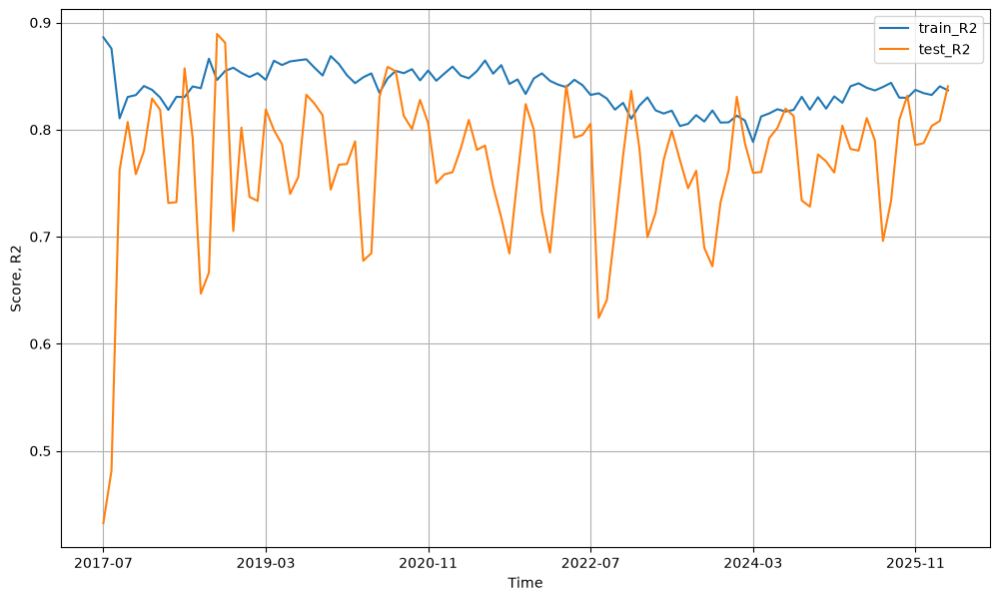

In [682]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12,7))

df_results.plot(y=["train_R2", "test_R2"], grid=True, ax=ax, xlabel="Time", ylabel="Score, R2")

#ax.xaxis.set_major_locator(mdates.YearLocator())
#ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Rolling-window result

Across the rolling evaluations, the model reaches an average training R² of about 0.84 and an average test R² of about 0.77. The mean train-test gap is approximately 0.07.

Earlier experiments showed that adding much older data did not improve prediction accuracy because the real-estate market changes over time. An 18-month rolling training window was therefore selected as a practical compromise between sample size and market recency.

This temporal result is lower than the random cross-validation score from 2016, as expected. It is also more representative of the real use case: predicting property values using only transactions that were available beforehand.